In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver




In [4]:
load_dotenv()


llm = ChatOpenAI()

In [5]:
class JokeState(TypedDict):
    joke: str
    explanation: str
    topic: str

In [11]:
def generateJoke(state: JokeState):
    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

def generateExp(state: JokeState):
    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

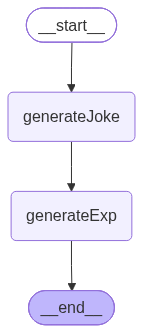

In [7]:
graph = StateGraph(JokeState)

graph.add_node('generateJoke', generateJoke)
graph.add_node('generateExp', generateExp)

graph.add_edge(START, 'generateJoke')
graph.add_edge('generateJoke', 'generateExp')
graph.add_edge('generateExp', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

workflow


In [8]:
config1 = {'configurable': {'thread_id': '1'}}
workflow.invoke({'topic': 'fruit'}, config=config1)

{'topic': 'fruit'}

In [9]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'fruit'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066f-610f-8002-c29a2594e476'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-12T09:59:34.245183+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066d-600b-8001-72f035f8db7d'}}, tasks=(), interrupts=())

In [10]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'fruit'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066f-610f-8002-c29a2594e476'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-12T09:59:34.245183+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066d-600b-8001-72f035f8db7d'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'fruit'}, next=('generateExp',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066d-600b-8001-72f035f8db7d'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-12T09:59:34.244338+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c623a-066b-6392-8000-11285e6d35d5'}}, tasks=(PregelTask(id='2ddbeffc-0816-04b4-5e36-79aab6a6a496', name='generateExp', path=('__pregel_pull', 'generateExp'), error=None, interrupts=(), s